# 02 · Imbalanced baselines

Results produced by `python -m threatsense.cli pipeline` (thresholds frozen on validation).

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from threatsense.common.config import get_settings
from threatsense.storage.database import Database

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 20)
db = Database(get_settings().db_path)
res = db.query_df("SELECT model, metrics_json, curves_json FROM model_results WHERE split='test'")
tbl = pd.DataFrame([{"model": m, **json.loads(j)} for m, j in zip(res.model, res.metrics_json)]).set_index("model")
tbl[["pr_auc", "roc_auc", "precision", "recall", "f1", "fpr", "alerts_per_10k"]].round(4)

,pr_auc,roc_auc,precision,recall,f1,fpr,alerts_per_10k
model,,,,,,,
majority_class,0.2105,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000
zscore_threshold,0.7326,0.8342,0.9684,0.6042,0.7441,0.0052,1313.5135
logistic_regression,0.9451,0.9391,0.9590,0.9320,0.9453,0.0106,2045.9459
random_forest,0.9828,0.9881,0.9599,0.9525,0.9562,0.0106,2089.1892
hist_gradient_boosting,0.9626,0.9627,0.9792,0.9469,0.9628,0.0054,2036.0360
isolation_forest,0.7898,0.8934,0.9218,0.5751,0.7083,0.0130,1313.5135
hybrid,0.9895,0.9912,0.9575,0.9833,0.9702,0.0116,2162.1622


* The **majority** baseline has ~79 % accuracy and zero recall — the reason accuracy is not reported.
* The **z-score** baseline is precise but misses ~40 % of attacks.

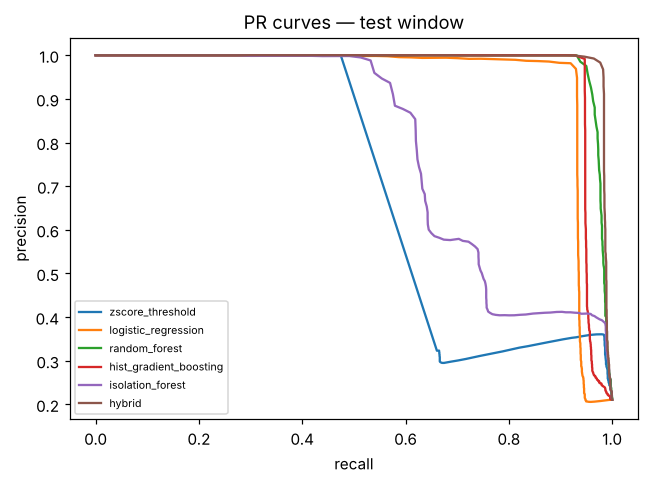

In [2]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for r in res.itertuples():
    if r.model == "majority_class":
        continue
    c = json.loads(r.curves_json)
    ax.plot(c["recall"], c["precision"], label=r.model)
ax.set(xlabel="recall", ylabel="precision", title="PR curves — test window")
ax.legend(fontsize=7)
plt.tight_layout()